In [1]:
from sklearn.datasets import load_iris
from skrules import SkopeRules

dataset = load_iris()
feature_names = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']
clf = SkopeRules(max_depth_duplication=2,
                 n_estimators=30,
                 precision_min=0.3,
                 recall_min=0.1,
                 feature_names=feature_names)

for idx, species in enumerate(dataset.target_names):
    X, y = dataset.data, dataset.target
    clf.fit(X, y == idx)
    rules = clf.rules_[0:3]
    print("Rules for iris", species)
    for rule in rules:
        print(rule)
    print()
    print(20*'=')
    print()

/home/sagemaker-user/explain/.venv/lib/python3.11/site-packages/sklearn/ensemble/_base.py:156: FutureWarning: `base_estimator` was renamed to `estimator` in version 1.2 and will be removed in 1.4.
  warnings.warn(
/home/sagemaker-user/explain/.venv/lib/python3.11/site-packages/sklearn/ensemble/_base.py:156: FutureWarning: `base_estimator` was renamed to `estimator` in version 1.2 and will be removed in 1.4.
  warnings.warn(


Rules for iris setosa
('petal_length <= 2.449999988079071', (1.0, 1.0, 19))
('petal_width <= 0.75', (1.0, 1.0, 6))




/home/sagemaker-user/explain/.venv/lib/python3.11/site-packages/sklearn/ensemble/_base.py:156: FutureWarning: `base_estimator` was renamed to `estimator` in version 1.2 and will be removed in 1.4.
  warnings.warn(
/home/sagemaker-user/explain/.venv/lib/python3.11/site-packages/sklearn/ensemble/_base.py:156: FutureWarning: `base_estimator` was renamed to `estimator` in version 1.2 and will be removed in 1.4.
  warnings.warn(


Rules for iris versicolor
('petal_length <= 4.8500001430511475 and petal_width <= 1.699999988079071 and petal_width > 0.800000011920929', (1.0, 1.0, 1))
('petal_length <= 4.75 and petal_length > 2.449999988079071', (0.9333333333333333, 0.9333333333333333, 1))
('petal_length <= 4.75 and petal_width > 0.800000011920929', (0.8819444444444444, 0.75, 2))




/home/sagemaker-user/explain/.venv/lib/python3.11/site-packages/sklearn/ensemble/_base.py:156: FutureWarning: `base_estimator` was renamed to `estimator` in version 1.2 and will be removed in 1.4.
  warnings.warn(
/home/sagemaker-user/explain/.venv/lib/python3.11/site-packages/sklearn/ensemble/_base.py:156: FutureWarning: `base_estimator` was renamed to `estimator` in version 1.2 and will be removed in 1.4.
  warnings.warn(


Rules for iris virginica
('petal_length > 4.8500001430511475 and petal_width > 1.699999988079071', (0.9230769230769231, 1.0, 1))
('petal_width > 1.6500000357627869', (0.8333333333333334, 0.9090909090909091, 1))
('petal_length > 4.950000047683716', (0.794973544973545, 0.8916666666666667, 3))




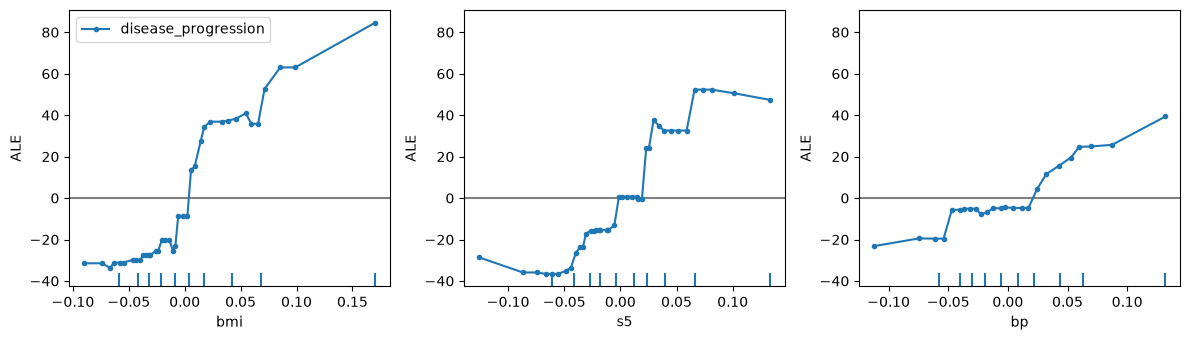

In [1]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import train_test_split
from alibi.explainers import ALE, plot_ale

data = load_diabetes()
X_train, X_test, y_train, y_test = train_test_split(data.data, data.target, random_state=0)
model = GradientBoostingRegressor(random_state=0).fit(X_train, y_train)

# The predictor takes a numpy array of shape (n, d) and returns shape (n,) or (n, k)
ale = ALE(model.predict,
          feature_names=data.feature_names,
          target_names=["disease_progression"])

exp = ale.explain(X_train)          # all features; use the training data (or a representative sample)

plot_ale(exp, features=["bmi", "s5", "bp"], n_cols=3,
         fig_kw={"figwidth": 12, "figheight": 3.5})
plt.show()

## ALE vs PDP with a correlated feature

We add `bmi_corr` = `bmi` + small noise (correlation ≈ 0.98) and compare ALE and PDP for both features.

- **PDP** varies one feature across its whole range while keeping the other features at their observed values. For example, it scores a patient with `bmi` = 0.15 and `bmi_corr` = -0.08, a combination that never appears in the data. The model's predictions there are extrapolation.
- **ALE** only measures prediction changes within small bins of real data points, so it stays on the data distribution.

corr(bmi, bmi_corr) = 0.981
test R^2 = 0.216
bmi       effect range  ALE =  87.7   PDP =  68.8
bmi_corr  effect range  ALE =  53.4   PDP =  39.6


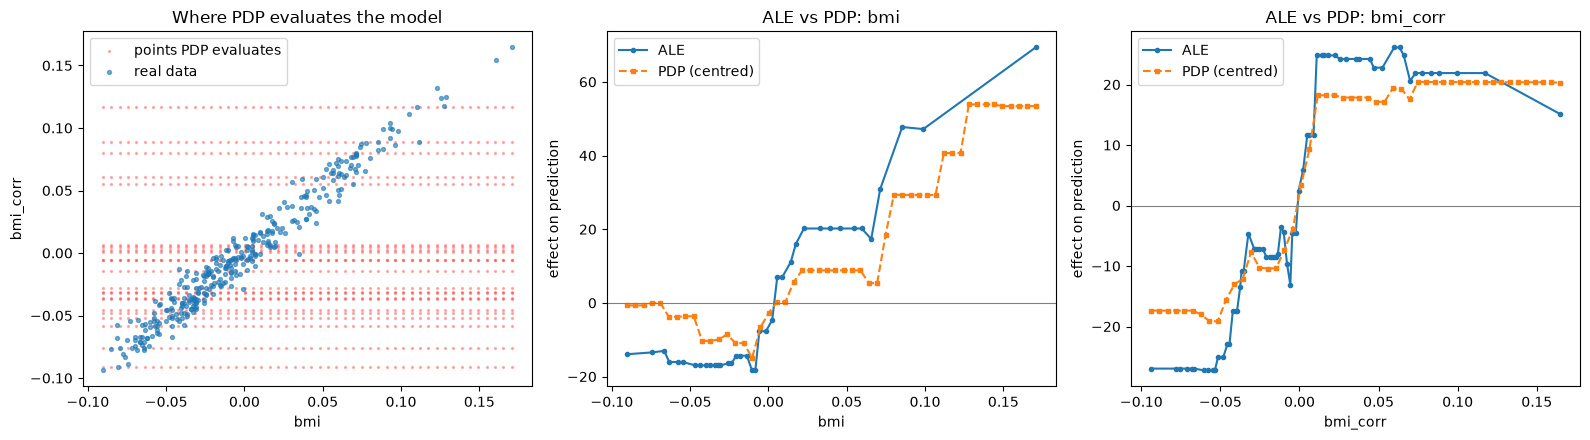

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import train_test_split
from alibi.explainers import ALE, PartialDependence

# --- Data: add a feature strongly correlated with bmi ---
data = load_diabetes()
X = data.data.copy()
feature_names = list(data.feature_names)

rng = np.random.default_rng(0)
bmi_idx = feature_names.index("bmi")
bmi_corr = X[:, bmi_idx] + rng.normal(0, 0.2 * X[:, bmi_idx].std(), size=len(X))
X = np.column_stack([X, bmi_corr])
feature_names.append("bmi_corr")
corr_idx = feature_names.index("bmi_corr")
print(f"corr(bmi, bmi_corr) = {np.corrcoef(X[:, bmi_idx], X[:, corr_idx])[0, 1]:.3f}")

X_train, X_test, y_train, y_test = train_test_split(X, data.target, random_state=0)
model = GradientBoostingRegressor(random_state=0).fit(X_train, y_train)
print(f"test R^2 = {model.score(X_test, y_test):.3f}")

# --- Explanations ---
feats = [bmi_idx, corr_idx]
ale_exp = ALE(model.predict, feature_names=feature_names,
              target_names=["disease_progression"]).explain(X_train, features=feats)
pd_exp = PartialDependence(model.predict, feature_names=feature_names,
                           target_names=["disease_progression"]).explain(
    X_train, features=feats, kind="average", grid_resolution=50)

# --- Plots ---
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Panel 1: real data vs the (bmi, bmi_corr) combinations PDP feeds the model
grid = np.linspace(X_train[:, bmi_idx].min(), X_train[:, bmi_idx].max(), 50)
gx, gy = np.meshgrid(grid, X_train[::15, corr_idx])   # subsample rows for readability
axes[0].scatter(gx, gy, s=2, c="red", alpha=0.25, label="points PDP evaluates")
axes[0].scatter(X_train[:, bmi_idx], X_train[:, corr_idx], s=8, alpha=0.6, label="real data")
axes[0].set(xlabel="bmi", ylabel="bmi_corr", title="Where PDP evaluates the model")
axes[0].legend(loc="upper left")

# Panels 2-3: ALE vs PDP. PDP is shifted to mean zero over the data so it shares
# the same baseline as ALE (ALE is centred by construction).
for ax, j in zip(axes[1:], range(len(feats))):
    ale_x, ale_y = ale_exp.feature_values[j], ale_exp.ale_values[j][:, 0]
    pd_x, pd_y = pd_exp.feature_values[j], pd_exp.pd_values[j][0]
    pd_centred = pd_y - np.interp(X_train[:, feats[j]], pd_x, pd_y).mean()

    ax.plot(ale_x, ale_y, "o-", ms=3, label="ALE")
    ax.plot(pd_x, pd_centred, "s--", ms=3, label="PDP (centred)")
    ax.axhline(0, c="grey", lw=0.8)
    name = feature_names[feats[j]]
    ax.set(xlabel=name, ylabel="effect on prediction", title=f"ALE vs PDP: {name}")
    ax.legend()
    print(f"{name:9s} effect range  ALE = {np.ptp(ale_y):5.1f}   PDP = {np.ptp(pd_y):5.1f}")

plt.tight_layout()
plt.show()

## When ALE and PDP show *different trends*

Correlation alone does not change the shape of a PDP. If the model is **additive** in a feature, i.e. `f(x) = g(x1) + h(rest)`, PDP and ALE give the same curve up to a constant, no matter how correlated the features are. In the diabetes example the gradient boosting model was close to additive in `bmi`/`bmi_corr`, so only the magnitude differed.

The trends diverge when two things happen together:
1. the features are correlated, **and**
2. the model has an **interaction** between them that behaves differently off the data than on it.

Example: `x2 ≈ x1` (corr ≈ 0.99), `y = x1·x2 + x3`. On the data `x1·x2 ≈ x1²`, so a change in `x1` really does move the prediction along a U-shape.
- **PDP** fixes `x1` and averages over *all* observed `x2`, mostly far from `x1`: `E[x1·x2] = x1·E[x2] ≈ 0`, so **flat**. That says "x1 has no effect", which is false for any realistic patient.
- **ALE** uses only nearby points, where `x2 ≈ x1`: local slope ≈ `x1`, so it integrates to a **U-shape**.

A model with an explicit interaction term (polynomial regression) extrapolates the product off the data and shows the gap. Tree ensembles extrapolate flat, so they hide it, which is why the GBM row looks similar for both methods.

corr(x1, x2) = 0.986
Polynomial regression (explicit x1*x2 term): R^2 = 0.994
Gradient boosting (trees): R^2 = 0.994


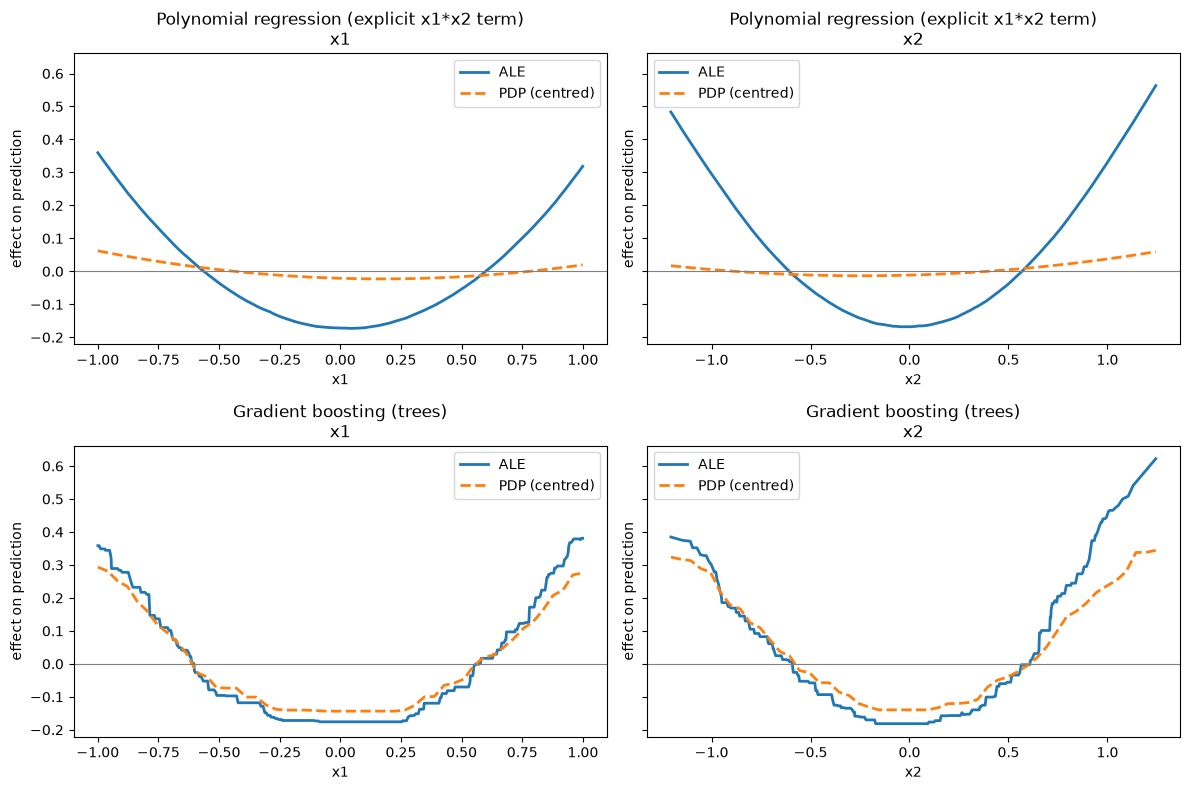

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import GradientBoostingRegressor
from alibi.explainers import ALE, PartialDependence

# --- Synthetic data: x2 is almost a copy of x1, target has an x1*x2 interaction ---
rng = np.random.default_rng(0)
n = 2000
x1 = rng.uniform(-1, 1, n)
x2 = x1 + rng.normal(0, 0.1, n)          # strongly correlated with x1
x3 = rng.uniform(-1, 1, n)               # independent feature
X_syn = np.column_stack([x1, x2, x3])
y_syn = x1 * x2 + x3 + rng.normal(0, 0.05, n)
syn_names = ["x1", "x2", "x3"]
print(f"corr(x1, x2) = {np.corrcoef(x1, x2)[0, 1]:.3f}")

models = {
    "Polynomial regression (explicit x1*x2 term)": make_pipeline(PolynomialFeatures(2), LinearRegression()),
    "Gradient boosting (trees)": GradientBoostingRegressor(random_state=0),
}

fig, axes = plt.subplots(len(models), 2, figsize=(12, 8), sharey=True)
for row, (title, mdl) in enumerate(models.items()):
    mdl.fit(X_syn, y_syn)
    feats = [0, 1]
    ale_s = ALE(mdl.predict, feature_names=syn_names).explain(X_syn, features=feats)
    pd_s = PartialDependence(mdl.predict, feature_names=syn_names).explain(
        X_syn, features=feats, kind="average", grid_resolution=50)
    print(f"{title}: R^2 = {mdl.score(X_syn, y_syn):.3f}")

    for col, j in enumerate(feats):
        ax = axes[row, col]
        ale_x, ale_y = ale_s.feature_values[col], ale_s.ale_values[col][:, 0]
        pd_x, pd_y = pd_s.feature_values[col], pd_s.pd_values[col][0]
        pd_centred = pd_y - np.interp(X_syn[:, j], pd_x, pd_y).mean()   # same baseline as ALE

        ax.plot(ale_x, ale_y, "-", lw=2, label="ALE")
        ax.plot(pd_x, pd_centred, "--", lw=2, label="PDP (centred)")
        ax.axhline(0, c="grey", lw=0.8)
        ax.set(xlabel=syn_names[j], ylabel="effect on prediction",
               title=f"{title}\n{syn_names[j]}")
        ax.legend()

plt.tight_layout()
plt.show()